# Reconstruction Performance of ILD@ILC and ILD@FCC-ee v02
## Invisible Higgs Analysis in $e^+e^- \to ZH$, $Z\to\mu^+\mu^-$

In [6]:
import uproot
import ROOT
import awkward as ak
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

## ILD@ILC

In [ ]:
ilc_file = uproot.open("data/ild_ilc_zh_25250_reco.root")
ilc_file.keys()

['events;4',
 'events;3',
 'configuration_metadata;1',
 'metadata;1',
 'podio_metadata;1']

In [8]:
ilc_events = ilc_file["events"]
print("ILC events:", ilc_events.num_entries)
ilc_events.keys()

ILC events: 25250


['Higgs',
 'Higgs/Higgs.PDG',
 'Higgs/Higgs.energy',
 'Higgs/Higgs.momentum.x',
 'Higgs/Higgs.momentum.y',
 'Higgs/Higgs.momentum.z',
 'Higgs/Higgs.referencePoint.x',
 'Higgs/Higgs.referencePoint.y',
 'Higgs/Higgs.referencePoint.z',
 'Higgs/Higgs.charge',
 'Higgs/Higgs.mass',
 'Higgs/Higgs.goodnessOfPID',
 'Higgs/Higgs.covMatrix.values[10]',
 'Higgs/Higgs.clusters_begin',
 'Higgs/Higgs.clusters_end',
 'Higgs/Higgs.tracks_begin',
 'Higgs/Higgs.tracks_end',
 'Higgs/Higgs.particles_begin',
 'Higgs/Higgs.particles_end',
 '_Higgs_clusters',
 '_Higgs_clusters/_Higgs_clusters.index',
 '_Higgs_clusters/_Higgs_clusters.collectionID',
 '_Higgs_tracks',
 '_Higgs_tracks/_Higgs_tracks.index',
 '_Higgs_tracks/_Higgs_tracks.collectionID',
 '_Higgs_particles',
 '_Higgs_particles/_Higgs_particles.index',
 '_Higgs_particles/_Higgs_particles.collectionID',
 '_Higgs_decayVertex',
 '_Higgs_decayVertex/_Higgs_decayVertex.index',
 '_Higgs_decayVertex/_Higgs_decayVertex.collectionID',
 'Muons_objIdx',
 'Muons

### Reconstructed Z and Higgs Recoil Masses

In [9]:
ilc_higgs_masses = ilc_events["Higgs/Higgs.mass"].array(library="ak")
ilc_higgs_masses = ak.flatten(ilc_higgs_masses)

ilc_z_masses = ilc_events["Z/Z.mass"].array(library="ak")
ilc_z_masses = ak.flatten(ilc_z_masses)

In [10]:
c_recoil = ROOT.TCanvas("c_recoil", "c_recoil", 800, 600)

h_higgs = ROOT.TH1F( "h_higgs", "ILD@ILC;Mass [GeV];Events", 50, 70, 160)
h_z = ROOT.TH1F( "h_z", "ILD@ILC;Mass [GeV];Events", 50, 70, 160)

for i in ilc_higgs_masses:
    h_higgs.Fill(float(i))

for i in ilc_z_masses:
    h_z.Fill(float(i))

h_higgs.SetLineWidth(2)
h_z.SetLineWidth(2)
h_z.SetLineColor(ROOT.kOrange + 1)
h_higgs.SetStats(0)
h_z.SetStats(0)

if h_higgs.GetMaximum() >= h_z.GetMaximum():
    h_higgs.Draw("HIST")
    h_z.Draw("HIST SAME")
else:
    h_z.Draw("HIST")
    h_higgs.Draw("HIST SAME")

legend = ROOT.TLegend(0.68, 0.75, 0.88, 0.88)
legend.AddEntry(h_higgs, "Higgs", "f")
legend.AddEntry(h_z, "Z", "f")
legend.Draw()

c_recoil.Draw()

### Choosing Two Reconstructed Muons

In [11]:
ilc_mu_indices = ilc_events["Muons_objIdx/Muons_objIdx.index"].array()

ilc_mu_indices
ak.num(ilc_mu_indices)

<Array [2, 1, 2, 2, 2, 1, 2, 3, ..., 2, 1, 3, 2, 2, 2, 2] type='25250 * int64'>

In [12]:
ilc_pass2mu = []

for i in range(len(ilc_mu_indices)):
    if len(ilc_mu_indices[i]) == 2:
        ilc_pass2mu.append(i)

print("# of ILC 2-muon events:", len(ilc_pass2mu))

# of ILC 2-muon events: 21249


### Additional Charged and Neutral PFOs

In [13]:
ilc_pfo_charge = ilc_events["PandoraPFOs/PandoraPFOs.charge"].array()

In [14]:
ilc_charged_counts = []
ilc_neutral_counts = []

for event_index in range(len(ilc_mu_indices)):

    if len(ilc_mu_indices[event_index]) != 2:
        continue

    selected_muons = set(ilc_mu_indices[event_index])

    n_charged = 0
    n_neutral = 0

    for i in range(len(ilc_pfo_charge[event_index])):

        if i in selected_muons:
            continue

        charge = ilc_pfo_charge[event_index][i]

        if charge == 0:
            n_neutral += 1
        else:
            n_charged += 1

    ilc_charged_counts.append(n_charged)
    ilc_neutral_counts.append(n_neutral)

In [15]:
c_charged = ROOT.TCanvas("c_charged", "c_charged", 800, 600)

h_charged = ROOT.TH1F("h_charged", "ILD@ILC;Number of additional charged PFOs;Events", max(ilc_charged_counts) + 1, -0.5, max(ilc_charged_counts) + 0.5)
h_charged.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)

for i in ilc_charged_counts:
    h_charged.Fill(i)

h_charged.Draw("HIST")
c_charged.Draw()

In [16]:
c_neutral = ROOT.TCanvas("c_neutral", "c_neutral", 800, 600)

h_neutral = ROOT.TH1F("h_neutral", "ILD@ILC;Number of additional neutral PFOs;Events", max(ilc_neutral_counts) + 1, -0.5, max(ilc_neutral_counts) + 0.5)
h_neutral.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)

for i in ilc_neutral_counts:
    h_neutral.Fill(i)

h_neutral.Draw("HIST")
c_neutral.Draw()

### Additional PFO Energy

In [17]:
ilc_pfo_energy = ilc_events["PandoraPFOs/PandoraPFOs.energy"].array()

In [18]:
ilc_ind_energies = []

for event_index in range(len(ilc_mu_indices)):

    if len(ilc_mu_indices[event_index]) != 2:
        continue

    selected_muons = set(ilc_mu_indices[event_index])

    for i in range(len(ilc_pfo_energy[event_index])):

        if i in selected_muons:
            continue

        energy = float(ilc_pfo_energy[event_index][i])
        ilc_ind_energies.append(energy)

print("Number of additional PFOs:", len(ilc_ind_energies))

Number of additional PFOs: 1042936


In [19]:
c_ind_energy = ROOT.TCanvas("c_ind_energy", "c_ind_energy", 800, 600)

h_ind_energy = ROOT.TH1F("h_ind_energy", "ILD@ILC;Additional PFO energy [GeV];PFOs", 60, 0, 30)
h_ind_energy.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)

for i in ilc_ind_energies:
    h_ind_energy.Fill(i)

h_ind_energy.Draw("HIST")
c_ind_energy.Draw()

In [20]:
ilc_tot_charged_energies = []
ilc_tot_neutral_energies = []

for event_index in range(len(ilc_mu_indices)):

    if len(ilc_mu_indices[event_index]) != 2:
        continue

    selected_muons = set(ilc_mu_indices[event_index])

    tot_charged_energy = 0.0
    tot_neutral_energy = 0.0

    for i in range(len(ilc_pfo_energy[event_index])):

        if i in selected_muons:
            continue

        energy = float(ilc_pfo_energy[event_index][i])
        charge = ilc_pfo_charge[event_index][i]

        if charge == 0:
            tot_neutral_energy += energy
        else:
            tot_charged_energy += energy

    ilc_tot_charged_energies.append(tot_charged_energy)
    ilc_tot_neutral_energies.append(tot_neutral_energy)


In [21]:
c_tot_charged_energy = ROOT.TCanvas("c_tot_charged_energy", "c_tot_charged_energy", 800, 600)

h_tot_charged_energy = ROOT.TH1F("h_tot_charged_energy", "ILD@ILC;Total additional charged PFO energy [GeV];Events", 50, 0, max(ilc_tot_charged_energies))
h_tot_charged_energy.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)

for i in ilc_tot_charged_energies:
    h_tot_charged_energy.Fill(i)

h_tot_charged_energy.Draw("HIST")
c_tot_charged_energy.Draw()

In [22]:
c_tot_neutral_energy = ROOT.TCanvas("c_tot_neutral_energy", "c_tot_neutral_energy", 800, 600)

h_tot_neutral_energy = ROOT.TH1F("h_tot_neutral_energy", "ILD@ILC;Total additional neutral PFO energy [GeV];Events", 30, 0, max(ilc_tot_neutral_energies))
h_tot_neutral_energy.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)

for i in ilc_tot_neutral_energies:
    h_tot_neutral_energy.Fill(i)

h_tot_neutral_energy.Draw("HIST")
c_tot_neutral_energy.Draw()

In [23]:
ilc_tot_energies = []

for i in range(len(ilc_tot_charged_energies)):
    tot_energy = (ilc_tot_charged_energies[i] + ilc_tot_neutral_energies[i])
    ilc_tot_energies.append(tot_energy)


In [24]:
c_tot_energy = ROOT.TCanvas("c_tot_energy", "c_tot_energy", 800, 600)

h_tot_energy = ROOT.TH1F("h_tot_energy", "ILD@ILC;Total additional PFO energy [GeV];Events", 30, 0, max(ilc_tot_energies))
h_tot_energy.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)

for i in ilc_tot_energies:
    h_tot_energy.Fill(i)

h_tot_energy.Draw("HIST")
c_tot_energy.Draw()

### Missing Transverse Momentum

In [25]:
ilc_pfo_px = ilc_events["PandoraPFOs/PandoraPFOs.momentum.x"].array()
ilc_pfo_py = ilc_events["PandoraPFOs/PandoraPFOs.momentum.y"].array()

In [26]:
ilc_missing_pts = []

for event_index in range(len(ilc_mu_indices)):

    if len(ilc_mu_indices[event_index]) != 2:
        continue

    tot_px = 0.0
    tot_py = 0.0

    for i in range(len(ilc_pfo_px[event_index])):

        tot_px += float(ilc_pfo_px[event_index][i])
        tot_py += float(ilc_pfo_py[event_index][i])

    missing_pt = float(np.hypot(tot_px, tot_py))
    ilc_missing_pts.append(missing_pt)

In [27]:
c_missing_pt = ROOT.TCanvas("c_missing_pt", "c_missing_pt", 800, 600)

h_missing_pt = ROOT.TH1F("h_missing_pt", "ILD@ILC;Missing p_{T} [GeV];Events", 50, 0, max(ilc_missing_pts))
h_missing_pt.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)

for i in ilc_missing_pts:
    h_missing_pt.Fill(i)

h_missing_pt.Draw("HIST")
c_missing_pt.Draw()

## ILD@FCC-ee v02

In [ ]:
fcc2_file = uproot.open("data/ild_fccee_v02_zh_25250_reco.root")
fcc2_file.keys()

['events;4',
 'events;3',
 'configuration_metadata;1',
 'metadata;1',
 'podio_metadata;1']

In [29]:
fcc2_events = fcc2_file["events"]
print("FCC-ee events:", fcc2_events.num_entries)
fcc2_events.keys()

FCC-ee events: 25250


['Higgs',
 'Higgs/Higgs.PDG',
 'Higgs/Higgs.energy',
 'Higgs/Higgs.momentum.x',
 'Higgs/Higgs.momentum.y',
 'Higgs/Higgs.momentum.z',
 'Higgs/Higgs.referencePoint.x',
 'Higgs/Higgs.referencePoint.y',
 'Higgs/Higgs.referencePoint.z',
 'Higgs/Higgs.charge',
 'Higgs/Higgs.mass',
 'Higgs/Higgs.goodnessOfPID',
 'Higgs/Higgs.covMatrix.values[10]',
 'Higgs/Higgs.clusters_begin',
 'Higgs/Higgs.clusters_end',
 'Higgs/Higgs.tracks_begin',
 'Higgs/Higgs.tracks_end',
 'Higgs/Higgs.particles_begin',
 'Higgs/Higgs.particles_end',
 '_Higgs_clusters',
 '_Higgs_clusters/_Higgs_clusters.index',
 '_Higgs_clusters/_Higgs_clusters.collectionID',
 '_Higgs_tracks',
 '_Higgs_tracks/_Higgs_tracks.index',
 '_Higgs_tracks/_Higgs_tracks.collectionID',
 '_Higgs_particles',
 '_Higgs_particles/_Higgs_particles.index',
 '_Higgs_particles/_Higgs_particles.collectionID',
 '_Higgs_decayVertex',
 '_Higgs_decayVertex/_Higgs_decayVertex.index',
 '_Higgs_decayVertex/_Higgs_decayVertex.collectionID',
 'Muons_objIdx',
 'Muons

### Reconstructed Z and Higgs Recoil Masses

In [30]:
fcc2_higgs_masses = fcc2_events["Higgs/Higgs.mass"].array(library="ak")
fcc2_higgs_masses = ak.flatten(fcc2_higgs_masses)

fcc2_z_masses = fcc2_events["Z/Z.mass"].array(library="ak")
fcc2_z_masses = ak.flatten(fcc2_z_masses)

In [31]:
c_recoil = ROOT.TCanvas("c_recoil", "c_recoil", 800, 600)

h_higgs = ROOT.TH1F( "h_higgs", "ILD@FCC-ee v02;Mass [GeV];Events", 50, 70, 160)
h_z = ROOT.TH1F( "h_z", "ILD@FCC-ee v02;Mass [GeV];Events", 50, 70, 160)

for i in fcc2_higgs_masses:
    h_higgs.Fill(float(i))

for i in fcc2_z_masses:
    h_z.Fill(float(i))

h_higgs.SetLineWidth(2)
h_z.SetLineWidth(2)
h_z.SetLineColor(ROOT.kOrange + 1)
h_higgs.SetStats(0)
h_z.SetStats(0)

if h_higgs.GetMaximum() >= h_z.GetMaximum():
    h_higgs.Draw("HIST")
    h_z.Draw("HIST SAME")
else:
    h_z.Draw("HIST")
    h_higgs.Draw("HIST SAME")

legend = ROOT.TLegend(0.68, 0.75, 0.88, 0.88)
legend.AddEntry(h_higgs, "Higgs", "f")
legend.AddEntry(h_z, "Z", "f")
legend.Draw()

c_recoil.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_recoil
Warning in <TROOT::Append>: Replacing existing TH1: h_higgs (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: h_z (Potential memory leak).


### Choosing Two Reconstructed Muons

In [32]:
fcc2_mu_indices = fcc2_events["Muons_objIdx/Muons_objIdx.index"].array()

fcc2_mu_indices
ak.num(fcc2_mu_indices)

<Array [1, 1, 2, 2, 2, 1, 2, 3, ..., 2, 1, 2, 2, 2, 2, 2] type='25250 * int64'>

In [33]:
fcc2_pass2mu = []

for i in range(len(fcc2_mu_indices)):
    if len(fcc2_mu_indices[i]) == 2:
        fcc2_pass2mu.append(i)

print("# of FCC-ee 2-muon events:", len(fcc2_pass2mu))

# of FCC-ee 2-muon events: 18200


### Additional Charged and Neutral PFOs

In [34]:
fcc2_pfo_charge = fcc2_events["PandoraPFOs/PandoraPFOs.charge"].array()

In [35]:
fcc2_charged_counts = []
fcc2_neutral_counts = []

for event_index in range(len(fcc2_mu_indices)):

    if len(fcc2_mu_indices[event_index]) != 2:
        continue

    selected_muons = set(fcc2_mu_indices[event_index])

    n_charged = 0
    n_neutral = 0

    for i in range(len(fcc2_pfo_charge[event_index])):

        if i in selected_muons:
            continue

        charge = fcc2_pfo_charge[event_index][i]

        if charge == 0:
            n_neutral += 1
        else:
            n_charged += 1

    fcc2_charged_counts.append(n_charged)
    fcc2_neutral_counts.append(n_neutral)

In [36]:
c_charged = ROOT.TCanvas("c_charged", "c_charged", 800, 600)

h_charged = ROOT.TH1F("h_charged", "ILD@FCC-ee v02;Number of additional charged PFOs;Events", max(fcc2_charged_counts) + 1, -0.5, max(fcc2_charged_counts) + 0.5)
h_charged.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)

for i in fcc2_charged_counts:
    h_charged.Fill(i)

h_charged.Draw("HIST")
c_charged.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_charged
Warning in <TROOT::Append>: Replacing existing TH1: h_charged (Potential memory leak).


In [37]:
c_neutral = ROOT.TCanvas("c_neutral", "c_neutral", 800, 600)

h_neutral = ROOT.TH1F("h_neutral", "ILD@FCC-ee v02;Number of additional neutral PFOs;Events", max(fcc2_neutral_counts) + 1, -0.5, max(fcc2_neutral_counts) + 0.5)
h_neutral.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)

for i in fcc2_neutral_counts:
    h_neutral.Fill(i)

h_neutral.Draw("HIST")
c_neutral.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_neutral
Warning in <TROOT::Append>: Replacing existing TH1: h_neutral (Potential memory leak).


### Additional PFO Energy

In [38]:
fcc2_pfo_energy = fcc2_events["PandoraPFOs/PandoraPFOs.energy"].array()

In [39]:
fcc2_ind_energies = []

for event_index in range(len(fcc2_mu_indices)):

    if len(fcc2_mu_indices[event_index]) != 2:
        continue

    selected_muons = set(fcc2_mu_indices[event_index])

    for i in range(len(fcc2_pfo_energy[event_index])):

        if i in selected_muons:
            continue

        energy = float(fcc2_pfo_energy[event_index][i])
        fcc2_ind_energies.append(energy)

print("Number of additional PFOs:", len(fcc2_ind_energies))

Number of additional PFOs: 846088


In [40]:
c_ind_energy = ROOT.TCanvas("c_ind_energy", "c_ind_energy", 800, 600)

h_ind_energy = ROOT.TH1F("h_ind_energy", "ILD@FCC-ee v02;Additional PFO energy [GeV];PFOs", 60, 0, 30)
h_ind_energy.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)

for i in fcc2_ind_energies:
    h_ind_energy.Fill(i)

h_ind_energy.Draw("HIST")
c_ind_energy.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_ind_energy
Warning in <TROOT::Append>: Replacing existing TH1: h_ind_energy (Potential memory leak).


In [41]:
fcc2_tot_charged_energies = []
fcc2_tot_neutral_energies = []

for event_index in range(len(fcc2_mu_indices)):

    if len(fcc2_mu_indices[event_index]) != 2:
        continue

    selected_muons = set(fcc2_mu_indices[event_index])

    tot_charged_energy = 0.0
    tot_neutral_energy = 0.0

    for i in range(len(fcc2_pfo_energy[event_index])):

        if i in selected_muons:
            continue

        energy = float(fcc2_pfo_energy[event_index][i])
        charge = fcc2_pfo_charge[event_index][i]

        if charge == 0:
            tot_neutral_energy += energy
        else:
            tot_charged_energy += energy

    fcc2_tot_charged_energies.append(tot_charged_energy)
    fcc2_tot_neutral_energies.append(tot_neutral_energy)

In [42]:
c_tot_charged_energy = ROOT.TCanvas("c_tot_charged_energy", "c_tot_charged_energy", 800, 600)

h_tot_charged_energy = ROOT.TH1F("h_tot_charged_energy", "ILD@FCC-ee v02;Total additional charged PFO energy [GeV];Events", 50, 0, max(fcc2_tot_charged_energies))
h_tot_charged_energy.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)

for i in fcc2_tot_charged_energies:
    h_tot_charged_energy.Fill(i)

h_tot_charged_energy.Draw("HIST")
c_tot_charged_energy.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_tot_charged_energy
Warning in <TROOT::Append>: Replacing existing TH1: h_tot_charged_energy (Potential memory leak).


In [43]:
c_tot_neutral_energy = ROOT.TCanvas("c_tot_neutral_energy", "c_tot_neutral_energy", 800, 600)

h_tot_neutral_energy = ROOT.TH1F("h_tot_neutral_energy", "ILD@FCC-ee v02;Total additional neutral PFO energy [GeV];Events", 30, 0, max(fcc2_tot_neutral_energies))
h_tot_neutral_energy.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)

for i in fcc2_tot_neutral_energies:
    h_tot_neutral_energy.Fill(i)

h_tot_neutral_energy.Draw("HIST")
c_tot_neutral_energy.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_tot_neutral_energy
Warning in <TROOT::Append>: Replacing existing TH1: h_tot_neutral_energy (Potential memory leak).


In [44]:
fcc2_tot_energies = []

for i in range(len(fcc2_tot_charged_energies)):
    tot_energy = (fcc2_tot_charged_energies[i] + fcc2_tot_neutral_energies[i])
    fcc2_tot_energies.append(tot_energy)

In [45]:
c_tot_energy = ROOT.TCanvas("c_tot_energy", "c_tot_energy", 800, 600)

h_tot_energy = ROOT.TH1F("h_tot_energy", "ILD@FCC-ee v02;Total additional PFO energy [GeV];Events", 30, 0, max(fcc2_tot_energies))
h_tot_energy.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)

for i in fcc2_tot_energies:
    h_tot_energy.Fill(i)

h_tot_energy.Draw("HIST")
c_tot_energy.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_tot_energy
Warning in <TROOT::Append>: Replacing existing TH1: h_tot_energy (Potential memory leak).


### Missing Transverse Momentum

In [46]:
fcc2_pfo_px = fcc2_events["PandoraPFOs/PandoraPFOs.momentum.x"].array()
fcc2_pfo_py = fcc2_events["PandoraPFOs/PandoraPFOs.momentum.y"].array()

In [47]:
fcc2_missing_pts = []

for event_index in range(len(fcc2_mu_indices)):

    if len(fcc2_mu_indices[event_index]) != 2:
        continue

    tot_px = 0.0
    tot_py = 0.0

    for i in range(len(fcc2_pfo_px[event_index])):

        tot_px += float(fcc2_pfo_px[event_index][i])
        tot_py += float(fcc2_pfo_py[event_index][i])

    missing_pt = float(np.hypot(tot_px, tot_py))
    fcc2_missing_pts.append(missing_pt)

In [48]:
c_missing_pt = ROOT.TCanvas("c_missing_pt", "c_missing_pt", 800, 600)

h_missing_pt = ROOT.TH1F("h_missing_pt", "ILD@FCC-ee v02;Missing p_{T} [GeV];Events", 50, 0, max(fcc2_missing_pts))
h_missing_pt.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)

for i in fcc2_missing_pts:
    h_missing_pt.Fill(i)

h_missing_pt.Draw("HIST")
c_missing_pt.Draw()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c_missing_pt
Warning in <TROOT::Append>: Replacing existing TH1: h_missing_pt (Potential memory leak).


## ILD@ILC vs ILD@FCC-ee v02

In [49]:
c_mass_compare = ROOT.TCanvas("c_mass_compare", "c_mass_compare", 900, 650)

h_fcc_recoil = ROOT.TH1F("h_fcc_recoil", "ILD@FCC-ee v02 vs ILD@ILC;Mass [GeV];Events", 50, 70, 160)
h_ilc_recoil = ROOT.TH1F("h_ilc_recoil", "ILD@FCC-ee v02 vs ILD@ILC;Mass [GeV];Events", 50, 70, 160)
h_fcc_z = ROOT.TH1F("h_fcc_z", "ILD@FCC-ee v02 vs ILD@ILC;Mass [GeV];Events", 50, 70, 160)
h_ilc_z = ROOT.TH1F("h_ilc_z", "ILD@FCC-ee v02 vs ILD@ILC;Mass [GeV];Events", 50, 70, 160)

for mass in fcc2_higgs_masses:
    h_fcc_recoil.Fill(float(mass))
for mass in ilc_higgs_masses:
    h_ilc_recoil.Fill(float(mass))

for mass in fcc2_z_masses:
    h_fcc_z.Fill(float(mass))
for mass in ilc_z_masses:
    h_ilc_z.Fill(float(mass))

for hist in [h_fcc_recoil, h_ilc_recoil, h_fcc_z, h_ilc_z]:
    if hist.Integral() > 0:
        hist.Scale(1.0 / hist.Integral())

h_fcc_recoil.SetLineWidth(1)
h_ilc_recoil.SetLineWidth(1)
h_fcc_recoil.SetLineColor(ROOT.kAzure + 1)
h_ilc_recoil.SetLineColor(ROOT.kOrange + 1)
h_fcc_recoil.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)
h_ilc_recoil.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)
h_fcc_z.SetLineWidth(2)
h_ilc_z.SetLineWidth(2)
h_ilc_z.SetLineColor(ROOT.kOrange + 1)
h_fcc_recoil.SetStats(0)
h_ilc_recoil.SetStats(0)
h_fcc_z.SetStats(0)
h_ilc_z.SetStats(0)

max_y = max(h_fcc_recoil.GetMaximum(), h_ilc_recoil.GetMaximum(), h_fcc_z.GetMaximum(), h_ilc_z.GetMaximum())
h_fcc_recoil.SetMaximum(max_y * 1.15)


h_fcc_recoil.Draw("HIST")
h_ilc_recoil.Draw("HIST SAME")
h_fcc_z.Draw("HIST SAME")
h_ilc_z.Draw("HIST SAME")

legend = ROOT.TLegend(0.62, 0.68, 0.88, 0.88)
legend.AddEntry(h_fcc_recoil, "FCC-ee v02 Higgs", "f")
legend.AddEntry(h_ilc_recoil, "ILC Higgs", "f")
legend.AddEntry(h_fcc_z, "FCC-ee v02 Z", "l")
legend.AddEntry(h_ilc_z, "ILC Z", "l")
legend.Draw()

c_mass_compare.Draw()

In [50]:
c_charged_compare = ROOT.TCanvas("c_charged_compare", "c_charged_compare", 800, 600)

max_charged = max(max(fcc2_charged_counts), max(ilc_charged_counts))

h_fcc_charged = ROOT.TH1F("h_fcc_charged", "ILD@FCC-ee v02 vs ILD@ILC Charged PFOs Distribution;# of additional charged PFOs;Events", max_charged + 1, -0.5, max_charged + 0.5)
h_ilc_charged = ROOT.TH1F("h_ilc_charged", "ILD@FCC-ee v02 vs ILD@ILC Charged PFOs Distribution;# of additional charged PFOs;Events", max_charged + 1, -0.5, max_charged + 0.5)

for i in fcc2_charged_counts:
    h_fcc_charged.Fill(i)
for i in ilc_charged_counts:
    h_ilc_charged.Fill(i)

if h_fcc_charged.Integral() > 0:
    h_fcc_charged.Scale(1.0 / h_fcc_charged.Integral())
if h_ilc_charged.Integral() > 0:
    h_ilc_charged.Scale(1.0 / h_ilc_charged.Integral())

h_fcc_charged.SetLineWidth(1)
h_ilc_charged.SetLineWidth(1)
h_fcc_charged.SetLineColor(ROOT.kAzure + 1)
h_ilc_charged.SetLineColor(ROOT.kOrange + 1)
h_fcc_charged.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)
h_ilc_charged.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)
h_fcc_charged.SetStats(0)
h_ilc_charged.SetStats(0)

if h_fcc_charged.GetMaximum() >= h_ilc_charged.GetMaximum():
    h_fcc_charged.Draw("HIST")
    h_ilc_charged.Draw("HIST SAME")
else:
    h_ilc_charged.Draw("HIST")
    h_fcc_charged.Draw("HIST SAME")

legend = ROOT.TLegend(0.68, 0.75, 0.88, 0.88)
legend.AddEntry(h_fcc_charged, "ILD@FCC-ee v02", "f")
legend.AddEntry(h_ilc_charged, "ILD@ILC", "f")
legend.Draw()

c_charged_compare.Draw()

In [51]:
c_neutral_compare = ROOT.TCanvas("c_neutral_compare", "c_neutral_compare", 800, 600)

max_neutral = max(max(fcc2_neutral_counts), max(ilc_neutral_counts))

h_fcc_neutral = ROOT.TH1F("h_fcc_neutral", "ILD@FCC-ee v02 vs ILD@ILC Neutral PFOs Distribution;# of additional neutral PFOs;Events", max_neutral + 1, -0.5, max_neutral + 0.5)
h_ilc_neutral = ROOT.TH1F("h_ilc_neutral", "ILD@FCC-ee v02 vs ILD@ILC Neutral PFOs Distribution;# of additional neutral PFOs;Events", max_neutral + 1, -0.5, max_neutral + 0.5)

for i in fcc2_neutral_counts:
    h_fcc_neutral.Fill(i)
for i in ilc_neutral_counts:
    h_ilc_neutral.Fill(i)

if h_fcc_neutral.Integral() > 0:
    h_fcc_neutral.Scale(1.0 / h_fcc_neutral.Integral())
if h_ilc_neutral.Integral() > 0:
    h_ilc_neutral.Scale(1.0 / h_ilc_neutral.Integral())

h_fcc_neutral.SetLineWidth(1)
h_ilc_neutral.SetLineWidth(1)
h_fcc_neutral.SetLineColor(ROOT.kAzure + 1)
h_ilc_neutral.SetLineColor(ROOT.kOrange + 1)
h_fcc_neutral.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)
h_ilc_neutral.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)
h_fcc_neutral.SetStats(0)
h_ilc_neutral.SetStats(0)

if h_fcc_neutral.GetMaximum() >= h_ilc_neutral.GetMaximum():
    h_fcc_neutral.Draw("HIST")
    h_ilc_neutral.Draw("HIST SAME")
else:
    h_ilc_neutral.Draw("HIST")
    h_fcc_neutral.Draw("HIST SAME")

legend = ROOT.TLegend(0.68, 0.75, 0.88, 0.88)
legend.AddEntry(h_fcc_neutral, "ILD@FCC-ee v02", "f")
legend.AddEntry(h_ilc_neutral, "ILD@ILC", "f")
legend.Draw()

c_neutral_compare.Draw()

In [52]:
c_ind_energy_compare = ROOT.TCanvas("c_ind_energy_compare", "c_ind_energy_compare", 800, 600)

max_ind_energy = max(max(fcc2_ind_energies), max(ilc_ind_energies))

h_fcc_ind_energy = ROOT.TH1F("h_fcc_ind_energy", "ILD@FCC-ee v02 vs ILD@ILC PFO Energy Distribution;Additional PFO energy [GeV];PFOs", 60, 0, 30)
h_ilc_ind_energy = ROOT.TH1F("h_ilc_ind_energy", "ILD@FCC-ee v02 vs ILD@ILC PFO Energy Distribution;Additional PFO energy [GeV];PFOs", 60, 0, 30)

for i in fcc2_ind_energies:
    h_fcc_ind_energy.Fill(i)
for i in ilc_ind_energies:
    h_ilc_ind_energy.Fill(i)

if h_fcc_ind_energy.Integral() > 0:
    h_fcc_ind_energy.Scale(1.0 / h_fcc_ind_energy.Integral())
if h_ilc_ind_energy.Integral() > 0:
    h_ilc_ind_energy.Scale(1.0 / h_ilc_ind_energy.Integral())

h_fcc_ind_energy.SetLineWidth(1)
h_ilc_ind_energy.SetLineWidth(1)
h_fcc_ind_energy.SetLineColor(ROOT.kAzure + 1)
h_ilc_ind_energy.SetLineColor(ROOT.kOrange + 1)
h_fcc_ind_energy.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)
h_ilc_ind_energy.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)
h_fcc_ind_energy.SetStats(0)
h_ilc_ind_energy.SetStats(0)

if h_fcc_ind_energy.GetMaximum() >= h_ilc_ind_energy.GetMaximum():
    h_fcc_ind_energy.Draw("HIST")
    h_ilc_ind_energy.Draw("HIST SAME")
else:
    h_ilc_ind_energy.Draw("HIST")
    h_fcc_ind_energy.Draw("HIST SAME")

legend = ROOT.TLegend(0.68, 0.75, 0.88, 0.88)
legend.AddEntry(h_fcc_ind_energy, "ILD@FCC-ee v02", "f")
legend.AddEntry(h_ilc_ind_energy, "ILD@ILC", "f")
legend.Draw()

c_ind_energy_compare.Draw()

In [53]:
c_tot_charged_compare = ROOT.TCanvas("c_tot_charged_compare", "c_tot_charged_compare", 800, 600)

max_tot_charged_energy = max(max(fcc2_tot_charged_energies), max(ilc_tot_charged_energies))

h_fcc_tot_charged = ROOT.TH1F("h_fcc_tot_charged", "ILD@FCC-ee v02 vs ILD@ILC Total Charged PFO Energy;Total additional charged PFO energy [GeV];Events", 70, 0, 140)
h_ilc_tot_charged = ROOT.TH1F("h_ilc_tot_charged", "ILD@FCC-ee v02 vs ILD@ILC Total Charged PFO Energy;Total additional charged PFO energy [GeV];Events", 70, 0, 140)

for i in fcc2_tot_charged_energies:
    h_fcc_tot_charged.Fill(i)
for i in ilc_tot_charged_energies:
    h_ilc_tot_charged.Fill(i)

if h_fcc_tot_charged.Integral() > 0:
    h_fcc_tot_charged.Scale(1.0 / h_fcc_tot_charged.Integral())
if h_ilc_tot_charged.Integral() > 0:
    h_ilc_tot_charged.Scale(1.0 / h_ilc_tot_charged.Integral())

h_fcc_tot_charged.SetLineWidth(1)
h_ilc_tot_charged.SetLineWidth(1)
h_fcc_tot_charged.SetLineColor(ROOT.kAzure + 1)
h_ilc_tot_charged.SetLineColor(ROOT.kOrange + 1)
h_fcc_tot_charged.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)
h_ilc_tot_charged.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)
h_fcc_tot_charged.SetStats(0)
h_ilc_tot_charged.SetStats(0)

if h_fcc_tot_charged.GetMaximum() >= h_ilc_tot_charged.GetMaximum():
    h_fcc_tot_charged.Draw("HIST")
    h_ilc_tot_charged.Draw("HIST SAME")
else:
    h_ilc_tot_charged.Draw("HIST")
    h_fcc_tot_charged.Draw("HIST SAME")

legend = ROOT.TLegend(0.68, 0.75, 0.88, 0.88)
legend.AddEntry(h_fcc_tot_charged, "ILD@FCC-ee v02", "f")
legend.AddEntry(h_ilc_tot_charged, "ILD@ILC", "f")
legend.Draw()

c_tot_charged_compare.Draw()

In [54]:
c_tot_neutral_compare = ROOT.TCanvas("c_tot_neutral_compare", "c_tot_neutral_compare", 800, 600)

max_tot_neutral_energy = max(max(fcc2_tot_neutral_energies), max(ilc_tot_neutral_energies))

h_fcc_tot_neutral = ROOT.TH1F("h_fcc_tot_neutral", "ILD@FCC-ee v02 vs ILD@ILC Total Neutral PFO Energy;Total additional neutral PFO energy [GeV];Events", 70, 0, 140)
h_ilc_tot_neutral = ROOT.TH1F("h_ilc_tot_neutral", "ILD@FCC-ee v02 vs ILD@ILC Total Neutral PFO Energy;Total additional neutral PFO energy [GeV];Events", 70, 0, 140)

for i in fcc2_tot_neutral_energies:
    h_fcc_tot_neutral.Fill(i)
for i in ilc_tot_neutral_energies:
    h_ilc_tot_neutral.Fill(i)

if h_fcc_tot_neutral.Integral() > 0:
    h_fcc_tot_neutral.Scale(1.0 / h_fcc_tot_neutral.Integral())
if h_ilc_tot_neutral.Integral() > 0:
    h_ilc_tot_neutral.Scale(1.0 / h_ilc_tot_neutral.Integral())

h_fcc_tot_neutral.SetLineWidth(1)
h_ilc_tot_neutral.SetLineWidth(1)
h_fcc_tot_neutral.SetLineColor(ROOT.kAzure + 1)
h_ilc_tot_neutral.SetLineColor(ROOT.kOrange + 1)
h_fcc_tot_neutral.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)
h_ilc_tot_neutral.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)
h_fcc_tot_neutral.SetStats(0)
h_ilc_tot_neutral.SetStats(0)

if h_fcc_tot_neutral.GetMaximum() >= h_ilc_tot_neutral.GetMaximum():
    h_fcc_tot_neutral.Draw("HIST")
    h_ilc_tot_neutral.Draw("HIST SAME")
else:
    h_ilc_tot_neutral.Draw("HIST")
    h_fcc_tot_neutral.Draw("HIST SAME")

legend = ROOT.TLegend(0.68, 0.75, 0.88, 0.88)
legend.AddEntry(h_fcc_tot_neutral, "ILD@FCC-ee v02", "f")
legend.AddEntry(h_ilc_tot_neutral, "ILD@ILC", "f")
legend.Draw()

c_tot_neutral_compare.Draw()

In [55]:
c_tot_energy_compare = ROOT.TCanvas("c_tot_energy_compare", "c_tot_energy_compare", 800, 600)

max_tot_energy = max(max(fcc2_tot_energies), max(ilc_tot_energies))

h_fcc_tot_energy = ROOT.TH1F("h_fcc_tot_energy", "ILD@FCC-ee v02 vs ILD@ILC Total Additional PFO Energy;Total additional PFO energy [GeV];Events", 100, 0, 200)
h_ilc_tot_energy = ROOT.TH1F("h_ilc_tot_energy", "ILD@FCC-ee v02 vs ILD@ILC Total Additional PFO Energy;Total additional PFO energy [GeV];Events", 100, 0, 200)

for i in fcc2_tot_energies:
    h_fcc_tot_energy.Fill(i)
for i in ilc_tot_energies:
    h_ilc_tot_energy.Fill(i)

if h_fcc_tot_energy.Integral() > 0:
    h_fcc_tot_energy.Scale(1.0 / h_fcc_tot_energy.Integral())
if h_ilc_tot_energy.Integral() > 0:
    h_ilc_tot_energy.Scale(1.0 / h_ilc_tot_energy.Integral())

h_fcc_tot_energy.SetLineWidth(1)
h_ilc_tot_energy.SetLineWidth(1)
h_fcc_tot_energy.SetLineColor(ROOT.kAzure + 1)
h_ilc_tot_energy.SetLineColor(ROOT.kOrange + 1)
h_fcc_tot_energy.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)
h_ilc_tot_energy.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)
h_fcc_tot_energy.SetStats(0)
h_ilc_tot_energy.SetStats(0)

if h_fcc_tot_energy.GetMaximum() >= h_ilc_tot_energy.GetMaximum():
    h_fcc_tot_energy.Draw("HIST")
    h_ilc_tot_energy.Draw("HIST SAME")
else:
    h_ilc_tot_energy.Draw("HIST")
    h_fcc_tot_energy.Draw("HIST SAME")

legend = ROOT.TLegend(0.68, 0.75, 0.88, 0.88)
legend.AddEntry(h_fcc_tot_energy, "ILD@FCC-ee v02", "f")
legend.AddEntry(h_ilc_tot_energy, "ILD@ILC", "f")
legend.Draw()

c_tot_energy_compare.Draw()

In [56]:
c_missing_pt_compare = ROOT.TCanvas("c_missing_pt_compare", "c_missing_pt_compare", 800, 600)

max_missing_pt = max(max(fcc2_missing_pts), max(ilc_missing_pts))

h_fcc_missing_pt = ROOT.TH1F("h_fcc_missing_pt", "ILD@FCC-ee v02 vs ILD@ILC Missing p_{T};Missing p_{T} [GeV];Events", 50, 0, max_missing_pt)
h_ilc_missing_pt = ROOT.TH1F("h_ilc_missing_pt", "ILD@FCC-ee v02 vs ILD@ILC Missing p_{T};Missing p_{T} [GeV];Events", 50, 0, max_missing_pt)

for i in fcc2_missing_pts:
    h_fcc_missing_pt.Fill(i)
for i in ilc_missing_pts:
    h_ilc_missing_pt.Fill(i)

if h_fcc_missing_pt.Integral() > 0:
    h_fcc_missing_pt.Scale(1.0 / h_fcc_missing_pt.Integral())
if h_ilc_missing_pt.Integral() > 0:
    h_ilc_missing_pt.Scale(1.0 / h_ilc_missing_pt.Integral())

h_fcc_missing_pt.SetLineWidth(1)
h_ilc_missing_pt.SetLineWidth(1)
h_fcc_missing_pt.SetLineColor(ROOT.kAzure + 1)
h_ilc_missing_pt.SetLineColor(ROOT.kOrange + 1)
h_fcc_missing_pt.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)
h_ilc_missing_pt.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)
h_fcc_missing_pt.SetStats(0)
h_ilc_missing_pt.SetStats(0)

if h_fcc_missing_pt.GetMaximum() >= h_ilc_missing_pt.GetMaximum():
    h_fcc_missing_pt.Draw("HIST")
    h_ilc_missing_pt.Draw("HIST SAME")
else:
    h_ilc_missing_pt.Draw("HIST")
    h_fcc_missing_pt.Draw("HIST SAME")

legend = ROOT.TLegend(0.68, 0.75, 0.88, 0.88)
legend.AddEntry(h_fcc_missing_pt, "ILD@FCC-ee v02", "f")
legend.AddEntry(h_ilc_missing_pt, "ILD@ILC", "f")
legend.Draw()

c_missing_pt_compare.Draw()

## Two-Muon Selection Efficiency

In [57]:
#two-muon selection efficiency for the full H -> ZZ* sample

n_ilc_total = len(ilc_mu_indices)
n_fcc2_total = len(fcc2_mu_indices)

n_ilc_2mu = len(ilc_pass2mu)
n_fcc2_2mu = len(fcc2_pass2mu)

print("ILD@ILC:")
print(f"Exactly 2 muons: {n_ilc_2mu}/{n_ilc_total}")
print(f"Efficiency: {100 * n_ilc_2mu / n_ilc_total:.2f}%")

print()

print("ILD@FCC-ee v02:")
print(f"Exactly 2 muons: {n_fcc2_2mu}/{n_fcc2_total}")
print(f"Efficiency: {100 * n_fcc2_2mu / n_fcc2_total:.2f}%")


ILD@ILC:
Exactly 2 muons: 21249/25250
Efficiency: 84.15%

ILD@FCC-ee v02:
Exactly 2 muons: 18200/25250
Efficiency: 72.08%


## Angular Acceptance

### Generator-Level Angular Information

In [ ]:
angles_all = pd.read_csv("data/zh_25250_truth_angles.csv")

angles_all.head()


,event_index,event_number,theta_mu1,theta_mu2,theta_min,status
0,0,1,19.288222,36.294076,19.288222,ok
1,1,2,79.310264,18.512367,18.512367,ok
2,2,3,87.968696,72.795175,72.795175,ok
3,3,4,29.949954,77.682114,29.949954,ok
4,4,5,77.341831,67.796622,67.796622,ok


In [ ]:
angle_bins = [0, 5, 7.5, 10, 12.5, 15, 17.5, 20, 22.5, 25, 27.5, 30, 32.5, 35, 40, 90]

angular_results = []

for low, high in zip(angle_bins[:-1], angle_bins[1:]):

    selected = angles_all[(angles_all["theta_min"] >= low) & (angles_all["theta_min"] < high)]

    indices = list(selected["event_index"])
    n_events = len(indices)

    n_ilc = sum(len(ilc_mu_indices[i]) == 2 for i in indices)
    n_fcc2 = sum(len(fcc2_mu_indices[i]) == 2 for i in indices)

    angular_results.append([
        f"{low}-{high}",
        n_events,
        round(100 * n_ilc / n_events, 2),
        round(100 * n_fcc2 / n_events, 2)])

angular_df = pd.DataFrame(
    angular_results,
    columns=[
        "Theta min [deg]",
        "Events",
        "ILC efficiency [%]",
        "FCC efficiency [%]"])

angular_df


,Theta min [deg],Events,ILC efficiency [%],FCC efficiency [%]
0,0-5,256,2.73,2.73
1,5-7.5,312,4.17,4.17
2,7.5-10,392,23.47,4.34
3,10-12.5,603,44.11,3.48
4,12.5-15,639,59.62,4.38
5,15-17.5,826,73.61,4.12
6,17.5-20,865,81.73,4.39
7,20-22.5,1008,85.12,9.42
8,22.5-25,975,85.95,52.10
9,25-27.5,1027,89.58,87.63


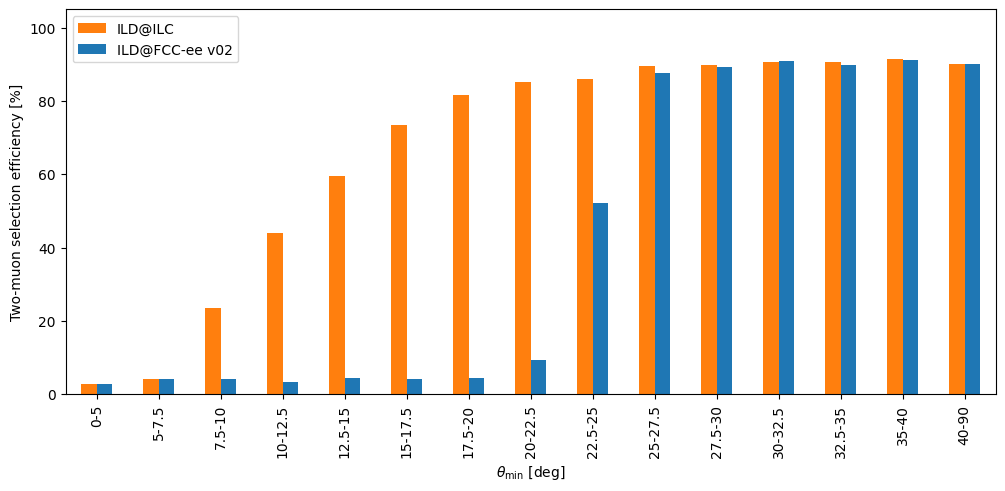

In [61]:
angular_df.plot(
    x="Theta min [deg]",
    y=["ILC efficiency [%]", "FCC efficiency [%]"],
    kind="bar",
    figsize=(12, 5),
    color=["tab:orange", "tab:blue"])

plt.xlabel(r"$\theta_{\min}$ [deg]")
plt.ylabel("Two-muon selection efficiency [%]")
plt.ylim(0, 105)
plt.legend(["ILD@ILC", "ILD@FCC-ee v02"])
plt.show()


### Common Angular Selection: $\theta_{\min}>25^\circ$

In [62]:
#two-muon selection
ilc_pass2 = []
fcc2_pass2 = []

for muons in ilc_mu_indices:
    ilc_pass2.append(len(muons) == 2)

for muons in fcc2_mu_indices:
    fcc2_pass2.append(len(muons) == 2)


# angular cut
pass25 = list(angles_all["theta_min"] > 25.0)
all_indices = list(angles_all["event_index"])

ilc_after25_2mu = []
fcc2_after25_2mu = []

for i in range(len(angles_all)):

    event_index = all_indices[i]

    if pass25[i] and ilc_pass2[event_index]:
        ilc_after25_2mu.append(event_index)

    if pass25[i] and fcc2_pass2[event_index]:
        fcc2_after25_2mu.append(event_index)


print("Total events:", len(angles_all))
print("Events with theta_min > 25 deg:", sum(pass25))
print()

print("ILC after angular cut + 2 muons:", len(ilc_after25_2mu))
print("FCC-ee v02 after angular cut + 2 muons:", len(fcc2_after25_2mu))


Total events: 25250
Events with theta_min > 25 deg: 19374

ILC after angular cut + 2 muons: 17479
FCC-ee v02 after angular cut + 2 muons: 17439


## Match Selected Events to PFO Observables

In [63]:
ilc_pos = {event: i for i, event in enumerate(ilc_pass2mu)}
fcc2_pos = {event: i for i, event in enumerate(fcc2_pass2mu)}

ilc_after25_pos = [ilc_pos[i] for i in ilc_after25_2mu]
fcc2_after25_pos = [fcc2_pos[i] for i in fcc2_after25_2mu]


# ILC
ilc_charged_25 = [ilc_charged_counts[i] for i in ilc_after25_pos]
ilc_neutral_25 = [ilc_neutral_counts[i] for i in ilc_after25_pos]
ilc_tot_energy_25 = [ilc_tot_energies[i] for i in ilc_after25_pos]
ilc_missing_pt_25 = [ilc_missing_pts[i] for i in ilc_after25_pos]


# FCC-ee v02
fcc2_charged_25 = [fcc2_charged_counts[i] for i in fcc2_after25_pos]
fcc2_neutral_25 = [fcc2_neutral_counts[i] for i in fcc2_after25_pos]
fcc2_tot_energy_25 = [fcc2_tot_energies[i] for i in fcc2_after25_pos]
fcc2_missing_pt_25 = [fcc2_missing_pts[i] for i in fcc2_after25_pos]

## Individual Cut Scans

In [64]:
charged_cuts = [0, 1, 2, 3]

print("CHARGED PFO CUT SCAN")
print()

for cut in charged_cuts:

    ilc_count = 0
    fcc2_count = 0

    for n_ch in ilc_charged_25:
        if n_ch <= cut:
            ilc_count += 1

    for n_ch in fcc2_charged_25:
        if n_ch <= cut:
            fcc2_count += 1

    print("N_ch <=", cut)
    print("ILC:", ilc_count, "/", len(ilc_charged_25), "=", 100.0 * ilc_count / len(ilc_charged_25), "%")
    print("FCC v02:", fcc2_count, "/", len(fcc2_charged_25), "=", 100.0 * fcc2_count / len(fcc2_charged_25), "%")
    print()

CHARGED PFO CUT SCAN

N_ch <= 0
ILC: 703 / 17479 = 4.021969220207105 %
FCC v02: 694 / 17439 = 3.9795859854349445 %

N_ch <= 1
ILC: 721 / 17479 = 4.124949939927913 %
FCC v02: 797 / 17439 = 4.570216182120534 %

N_ch <= 2
ILC: 1167 / 17479 = 6.676583328565707 %
FCC v02: 1153 / 17439 = 6.611617638626068 %

N_ch <= 3
ILC: 1202 / 17479 = 6.8768236169117225 %
FCC v02: 1270 / 17439 = 7.282527667870864 %



In [65]:
neutral_cuts = [0, 1, 2, 3]

print("NEUTRAL PFO CUT SCAN")
print()

for cut in neutral_cuts:

    ilc_count = 0
    fcc2_count = 0

    for n_neu in ilc_neutral_25:
        if n_neu <= cut:
            ilc_count += 1

    for n_neu in fcc2_neutral_25:
        if n_neu <= cut:
            fcc2_count += 1

    print("N_neu <=", cut)
    print("ILC:", ilc_count, "/", len(ilc_neutral_25), "=", 100.0 * ilc_count / len(ilc_neutral_25), "%")
    print("FCC v02:", fcc2_count, "/", len(fcc2_neutral_25), "=", 100.0 * fcc2_count / len(fcc2_neutral_25), "%")
    print()

NEUTRAL PFO CUT SCAN

N_neu <= 0
ILC: 362 / 17479 = 2.0710566966073576 %
FCC v02: 361 / 17439 = 2.0700728252766787 %

N_neu <= 1
ILC: 655 / 17479 = 3.747353967618285 %
FCC v02: 679 / 17439 = 3.8935718791215095 %

N_neu <= 2
ILC: 873 / 17479 = 4.994564906459179 %
FCC v02: 881 / 17439 = 5.051895177475773 %

N_neu <= 3
ILC: 1008 / 17479 = 5.766920304365239 %
FCC v02: 1026 / 17439 = 5.883364871838982 %



In [66]:
energy_cuts = [2, 5, 10, 15, 20, 30]

print("TOTAL ADDITIONAL PFO ENERGY CUT SCAN")
print()

for cut in energy_cuts:

    ilc_count = 0
    fcc2_count = 0

    for energy in ilc_tot_energy_25:
        if energy < cut:
            ilc_count += 1

    for energy in fcc2_tot_energy_25:
        if energy < cut:
            fcc2_count += 1

    print("E_add <", cut, "GeV")
    print("ILC:", ilc_count, "/", len(ilc_tot_energy_25), "=", 100.0 * ilc_count / len(ilc_tot_energy_25), "%")
    print("FCC v02:", fcc2_count, "/", len(fcc2_tot_energy_25), "=", 100.0 * fcc2_count / len(fcc2_tot_energy_25), "%")
    print()

TOTAL ADDITIONAL PFO ENERGY CUT SCAN

E_add < 2 GeV
ILC: 526 / 17479 = 3.0093254762858286 %
FCC v02: 536 / 17439 = 3.0735707322667585 %

E_add < 5 GeV
ILC: 595 / 17479 = 3.4040849018822588 %
FCC v02: 617 / 17439 = 3.5380469063593094 %

E_add < 10 GeV
ILC: 657 / 17479 = 3.7587962698094857 %
FCC v02: 663 / 17439 = 3.8018234990538446 %

E_add < 15 GeV
ILC: 695 / 17479 = 3.976200011442302 %
FCC v02: 706 / 17439 = 4.048397270485693 %

E_add < 20 GeV
ILC: 743 / 17479 = 4.250815264031123 %
FCC v02: 781 / 17439 = 4.47846780205287 %

E_add < 30 GeV
ILC: 1216 / 17479 = 6.956919732250129 %
FCC v02: 1345 / 17439 = 7.712598199438041 %



In [67]:
pt_cuts = [5, 10, 15, 20, 25, 30, 40, 50]

print("MISSING PT CUT SCAN")
print()

for cut in pt_cuts:

    ilc_count = 0
    fcc2_count = 0

    for pt in ilc_missing_pt_25:
        if pt > cut:
            ilc_count += 1

    for pt in fcc2_missing_pt_25:
        if pt > cut:
            fcc2_count += 1

    print("pTmiss >", cut, "GeV")

    print("ILC:", ilc_count, "/", len(ilc_missing_pt_25), "=", 100.0 * ilc_count / len(ilc_missing_pt_25), "%")
    print("FCC v02:", fcc2_count, "/", len(fcc2_missing_pt_25), "=", 100.0 * fcc2_count / len(fcc2_missing_pt_25), "%")
    print()

MISSING PT CUT SCAN

pTmiss > 5 GeV
ILC: 9770 / 17479 = 55.895646204016245 %
FCC v02: 10617 / 17439 = 60.88078444864958 %

pTmiss > 10 GeV
ILC: 7168 / 17479 = 41.00921105326392 %
FCC v02: 7321 / 17439 = 41.980618154710704 %

pTmiss > 15 GeV
ILC: 6022 / 17479 = 34.452771897705816 %
FCC v02: 6072 / 17439 = 34.81851023567865 %

pTmiss > 20 GeV
ILC: 5031 / 17479 = 28.78311116196579 %
FCC v02: 5062 / 17439 = 29.026893743907333 %

pTmiss > 25 GeV
ILC: 4150 / 17479 = 23.742777046741804 %
FCC v02: 4141 / 17439 = 23.7456276162624 %

pTmiss > 30 GeV
ILC: 3358 / 17479 = 19.21162537902626 %
FCC v02: 3341 / 17439 = 19.15820861287918 %

pTmiss > 40 GeV
ILC: 2037 / 17479 = 11.653984781738085 %
FCC v02: 2010 / 17439 = 11.525890246000344 %

pTmiss > 50 GeV
ILC: 1135 / 17479 = 6.4935064935064934 %
FCC v02: 1086 / 17439 = 6.227421297092723 %



## Sequential Selection, Efficiency, and Purity

### Cumulative Event Selection

In [69]:
#FINAL SEQUENTIAL CUTFLOW

# ---------- ILC ----------

ilc_step0 = list(range(len(ilc_charged_25)))

# N_ch = 0
ilc_step1 = []

for i in ilc_step0:
    if ilc_charged_25[i] == 0:
        ilc_step1.append(i)


# N_neu <= 2
ilc_step2 = []

for i in ilc_step1:
    if ilc_neutral_25[i] <= 2:
        ilc_step2.append(i)


# E_add < 20 GeV
ilc_step3 = []

for i in ilc_step2:
    if ilc_tot_energy_25[i] < 20:
        ilc_step3.append(i)


# pTmiss > 20 GeV (test only)
ilc_step4 = []

for i in ilc_step3:
    if ilc_missing_pt_25[i] > 20:
        ilc_step4.append(i)


# ---------- FCC-ee v02 ----------

fcc2_step0 = list(range(len(fcc2_charged_25)))

# N_ch = 0
fcc2_step1 = []

for i in fcc2_step0:
    if fcc2_charged_25[i] == 0:
        fcc2_step1.append(i)


# N_neu <= 2
fcc2_step2 = []

for i in fcc2_step1:
    if fcc2_neutral_25[i] <= 2:
        fcc2_step2.append(i)


# E_add < 20 GeV
fcc2_step3 = []

for i in fcc2_step2:
    if fcc2_tot_energy_25[i] < 20:
        fcc2_step3.append(i)


# pTmiss > 20 GeV
fcc2_step4 = []

for i in fcc2_step3:
    if fcc2_missing_pt_25[i] > 20:
        fcc2_step4.append(i)


### Full-Sample Cutflow

In [70]:
steps = [
    ("Total events", 25250, 25250),
    ("Exactly 2 muons", len(ilc_pass2mu), len(fcc2_pass2mu)),
    ("+ theta_min > 25 deg", len(ilc_step0), len(fcc2_step0)),
    ("+ N_ch = 0", len(ilc_step1), len(fcc2_step1)),
    ("+ N_neu <= 2", len(ilc_step2), len(fcc2_step2)),
    ("+ E_add < 20 GeV", len(ilc_step3), len(fcc2_step3)),
    ("+ pTmiss > 20 GeV", len(ilc_step4), len(fcc2_step4))]

for name, ilc, fcc2 in steps:
    print(name)
    print("ILC:", ilc)
    print("FCC-ee v02:", fcc2)
    print()


cutflow_df = pd.DataFrame(steps, columns=["Selection", "ILC", "FCC-ee v02"])
cutflow_df["ILC efficiency [%]"] = (100 * cutflow_df["ILC"] / 25250).round(2)
cutflow_df["FCC-ee v02 efficiency [%]"] = (100 * cutflow_df["FCC-ee v02"] / 25250).round(2)

cutflow_df


Total events
ILC: 25250
FCC-ee v02: 25250

Exactly 2 muons
ILC: 21249
FCC-ee v02: 18200

+ theta_min > 25 deg
ILC: 17479
FCC-ee v02: 17439

+ N_ch = 0
ILC: 703
FCC-ee v02: 694

+ N_neu <= 2
ILC: 688
FCC-ee v02: 670

+ E_add < 20 GeV
ILC: 663
FCC-ee v02: 656

+ pTmiss > 20 GeV
ILC: 610
FCC-ee v02: 605



,Selection,ILC,FCC-ee v02,ILC efficiency [%],FCC-ee v02 efficiency [%]
0,Total events,25250,25250,100.00,100.00
1,Exactly 2 muons,21249,18200,84.15,72.08
2,+ theta_min > 25 deg,17479,17439,69.22,69.07
3,+ N_ch = 0,703,694,2.78,2.75
4,+ N_neu <= 2,688,670,2.72,2.65
5,+ E_add < 20 GeV,663,656,2.63,2.60
6,+ pTmiss > 20 GeV,610,605,2.42,2.40


### Truth $4\nu$ Check and Signal Purity

In [ ]:
#Truth 4nu events
angle_4nu = pd.read_csv("data/zh_25250_truth_4nu.csv")
four_nu_indices = set(angle_4nu["event_index"])

ilc_final = [ilc_after25_2mu[i] for i in ilc_step3]
fcc2_final = [fcc2_after25_2mu[i] for i in fcc2_step3]

for name, selected in [("ILC", ilc_final), ("FCC-ee v02", fcc2_final)]:

    n_signal = sum(i in four_nu_indices for i in selected)
    n_visible = len(selected) - n_signal

    print(name)
    print("Total selected:", len(selected))
    print("Truth 4nu:", n_signal)
    print("Visible decays:", n_visible)
    print("Signal purity:", round(100 * n_signal / len(selected), 2), "%")
    print("Signal efficiency:", round(100 * n_signal / len(four_nu_indices), 2), "%")
    print()


ILC
Total selected: 663
Truth 4nu: 663
Visible decays: 0
Signal purity: 100.0 %
Signal efficiency: 66.17 %

FCC-ee v02
Total selected: 656
Truth 4nu: 655
Visible decays: 1
Signal purity: 99.85 %
Signal efficiency: 65.37 %



In [72]:
steps_4nu = [
    ("Generated 4nu events", list(four_nu_indices), list(four_nu_indices)),
    ("Exactly 2 muons", ilc_pass2mu, fcc2_pass2mu),
    ("+ theta_min > 25 deg", ilc_after25_2mu, fcc2_after25_2mu),
    ("+ N_ch = 0",
     [ilc_after25_2mu[i] for i in ilc_step1],
     [fcc2_after25_2mu[i] for i in fcc2_step1]),
    ("+ N_neu <= 2",
     [ilc_after25_2mu[i] for i in ilc_step2],
     [fcc2_after25_2mu[i] for i in fcc2_step2]),
    ("+ E_add < 20 GeV", ilc_final, fcc2_final),
    ("+ pTmiss > 20 GeV",
     [ilc_after25_2mu[i] for i in ilc_step4],
     [fcc2_after25_2mu[i] for i in fcc2_step4])]

signal_results = []

for name, ilc_events_step, fcc2_events_step in steps_4nu:

    ilc_signal = sum(i in four_nu_indices for i in ilc_events_step)
    fcc2_signal = sum(i in four_nu_indices for i in fcc2_events_step)

    signal_results.append([name, ilc_signal, fcc2_signal])

signal_df = pd.DataFrame( signal_results, columns=["Selection", "ILC 4nu", "FCC-ee v02 4nu"])
signal_df["ILC efficiency [%]"] = (100 * signal_df["ILC 4nu"] / len(four_nu_indices)).round(2)
signal_df["FCC-ee v02 efficiency [%]"] = (100 * signal_df["FCC-ee v02 4nu"] / len(four_nu_indices)).round(2)

signal_df


,Selection,ILC 4nu,FCC-ee v02 4nu,ILC efficiency [%],FCC-ee v02 efficiency [%]
0,Generated 4nu events,1002,1002,100.00,100.00
1,Exactly 2 muons,907,738,90.52,73.65
2,+ theta_min > 25 deg,712,710,71.06,70.86
3,+ N_ch = 0,703,687,70.16,68.56
4,+ N_neu <= 2,688,668,68.66,66.67
5,+ E_add < 20 GeV,663,655,66.17,65.37
6,+ pTmiss > 20 GeV,610,604,60.88,60.28


### Missing-$p_T$ Cut Test

In [73]:
#Test the missing pT cut

for name, after25, step3, step4 in [("ILC", ilc_after25_2mu, ilc_step3, ilc_step4), ("FCC-ee v02", fcc2_after25_2mu, fcc2_step3, fcc2_step4)]:

    final_events = [after25[i] for i in step3]
    pt_events = [after25[i] for i in step4]

    signal_final = sum(i in four_nu_indices for i in final_events)
    signal_pt = sum(i in four_nu_indices for i in pt_events)

    visible_final = len(final_events) - signal_final
    visible_pt = len(pt_events) - signal_pt

    print(name)
    print("Without pT cut:", signal_final, "signal,", visible_final, "visible")
    print("With pT > 20:", signal_pt, "signal,", visible_pt, "visible")
    print("Signal lost:", signal_final - signal_pt)
    print("Visible rejected:", visible_final - visible_pt)
    print()


ILC
Without pT cut: 663 signal, 0 visible
With pT > 20: 610 signal, 0 visible
Signal lost: 53
Visible rejected: 0

FCC-ee v02
Without pT cut: 655 signal, 1 visible
With pT > 20: 604 signal, 1 visible
Signal lost: 51
Visible rejected: 0



### Combined Efficiency Comparison

In [74]:
#COMBINED SELECTION EFFICIENCY TABLE

comparison_df = pd.merge(
    signal_df,
    cutflow_df,
    on="Selection",
    suffixes=("_4nu", "_full"))

comparison_df = comparison_df[[
    "Selection",
    "ILC efficiency [%]_4nu",
    "ILC efficiency [%]_full",
    "FCC-ee v02 efficiency [%]_4nu",
    "FCC-ee v02 efficiency [%]_full"]]

comparison_df.columns = [
    "Selection step",
    "4nu efficiency ILC [%]",
    "Full H -> ZZ* efficiency ILC [%]",
    "4nu efficiency FCC-ee v02 [%]",
    "Full H -> ZZ* efficiency FCC-ee v02 [%]"]

comparison_df.iloc[:-1]


,Selection step,4nu efficiency ILC [%],Full H -> ZZ* efficiency ILC [%],4nu efficiency FCC-ee v02 [%],Full H -> ZZ* efficiency FCC-ee v02 [%]
0,Exactly 2 muons,90.52,84.15,73.65,72.08
1,+ theta_min > 25 deg,71.06,69.22,70.86,69.07
2,+ N_ch = 0,70.16,2.78,68.56,2.75
3,+ N_neu <= 2,68.66,2.72,66.67,2.65
4,+ E_add < 20 GeV,66.17,2.63,65.37,2.60


## Final Reconstructed Mass Comparison

In [75]:
ilc_final = []
fcc2_final = []

# ILC
for i in ilc_step3:
    event_index = ilc_after25_2mu[i]
    ilc_final.append(event_index)

# FCC-ee v02
for i in fcc2_step3:
    event_index = fcc2_after25_2mu[i]
    fcc2_final.append(event_index)

In [76]:
ilc_z_by_event = {}
ilc_recoil_by_event = {}

for i in range(len(ilc_pass2mu)):
    event_index = ilc_pass2mu[i]

    ilc_z_by_event[event_index] = float(ilc_z_masses[i])
    ilc_recoil_by_event[event_index] = float(ilc_higgs_masses[i])


fcc2_z_by_event = {}
fcc2_recoil_by_event = {}

for i in range(len(fcc2_pass2mu)):
    event_index = fcc2_pass2mu[i]

    fcc2_z_by_event[event_index] = float(fcc2_z_masses[i])
    fcc2_recoil_by_event[event_index] = float(fcc2_higgs_masses[i])

In [77]:
ilc_z_final = []
fcc2_z_final = []

ilc_recoil_final = []
fcc2_recoil_final = []

for event_index in ilc_final:
    ilc_z_final.append(ilc_z_by_event[event_index])
    ilc_recoil_final.append(ilc_recoil_by_event[event_index])

for event_index in fcc2_final:
    fcc2_z_final.append(fcc2_z_by_event[event_index])
    fcc2_recoil_final.append(fcc2_recoil_by_event[event_index])

In [78]:
ROOT.gStyle.SetOptStat(0)

c_mass_final = ROOT.TCanvas("c_mass_final", "Final Z and Higgs Mass Comparison", 900, 650)

h_ilc_z_final = ROOT.TH1F("h_ilc_z_final", "", 70, 70, 160)
h_fcc2_z_final = ROOT.TH1F("h_fcc2_z_final", "", 70, 70, 160)

h_ilc_recoil_final = ROOT.TH1F("h_ilc_recoil_final", "", 70, 70, 160)
h_fcc2_recoil_final = ROOT.TH1F("h_fcc2_recoil_final", "", 70, 70, 160)

for mass in ilc_z_final:
    h_ilc_z_final.Fill(mass)
for mass in fcc2_z_final:
    h_fcc2_z_final.Fill(mass)

for mass in ilc_recoil_final:
    h_ilc_recoil_final.Fill(mass)
for mass in fcc2_recoil_final:
    h_fcc2_recoil_final.Fill(mass)

histograms = [h_ilc_z_final, h_fcc2_z_final, h_ilc_recoil_final, h_fcc2_recoil_final]

for hist in histograms:
    if hist.Integral() > 0:
        hist.Scale(1.0 / hist.Integral())


h_ilc_z_final.SetLineColor(ROOT.kOrange + 1)
h_ilc_z_final.SetLineWidth(2)
h_fcc2_z_final.SetLineWidth(2)

h_ilc_recoil_final.SetLineColor(ROOT.kOrange + 1)
h_ilc_recoil_final.SetLineWidth(1)
h_ilc_recoil_final.SetFillColorAlpha(ROOT.kOrange + 7, 0.30)
h_fcc2_recoil_final.SetLineColor(ROOT.kAzure + 1)
h_fcc2_recoil_final.SetLineWidth(1)
h_fcc2_recoil_final.SetFillColorAlpha(ROOT.kAzure + 1, 0.30)

h_ilc_z_final.SetTitle("Z/Higgs Recoil Mass Distribution for ILD@ILC and ILD@FCC-ee")
h_ilc_z_final.GetXaxis().SetTitle("Mass [GeV]")
h_ilc_z_final.GetYaxis().SetTitle("Events")


max_height = 0

for hist in histograms:
    if hist.GetMaximum() > max_height:
        max_height = hist.GetMaximum()

h_ilc_z_final.SetMaximum(1.25 * max_height)


h_ilc_z_final.Draw("HIST")
h_fcc2_z_final.Draw("HIST SAME")
h_ilc_recoil_final.Draw("HIST SAME")
h_fcc2_recoil_final.Draw("HIST SAME")



z_line = ROOT.TLine(91.1876, 0, 91.1876, 1.25 * max_height)
z_line.SetLineColor(ROOT.kBlack)
z_line.SetLineStyle(7)
z_line.SetLineWidth(2)
z_line.Draw("SAME")

higgs_line = ROOT.TLine(125.0, 0, 125.0, 1.25 * max_height)
higgs_line.SetLineColor(ROOT.kBlack)
higgs_line.SetLineStyle(7)
higgs_line.SetLineWidth(2)
higgs_line.Draw("SAME")

legend_mass = ROOT.TLegend( 0.58, 0.57, 0.88, 0.88)
legend_mass.AddEntry(h_ilc_z_final, "ILD@ILC - Z", "l")
legend_mass.AddEntry(h_fcc2_z_final, "ILD@FCC-ee v02 - Z", "l")
legend_mass.AddEntry(h_ilc_recoil_final, "ILD@ILC - Higgs", "f")
legend_mass.AddEntry(h_fcc2_recoil_final, "ILD@FCC-ee v02 - Higgs", "f")
legend_mass.Draw()

c_mass_final.Draw()

In [79]:
mass_stats = pd.DataFrame({
    "Detector": [
        "ILD@ILC",
        "ILD@FCC-ee v02",
        "ILD@ILC",
        "ILD@FCC-ee v02"],

    "Observable": [
        "Z mass",
        "Z mass",
        "Higgs recoil mass",
        "Higgs recoil mass"],

    "Mean [GeV]": [
        np.mean(ilc_z_final),
        np.mean(fcc2_z_final),
        np.mean(ilc_recoil_final),
        np.mean(fcc2_recoil_final)],

    "Std [GeV]": [
        np.std(ilc_z_final),
        np.std(fcc2_z_final),
        np.std(ilc_recoil_final),
        np.std(fcc2_recoil_final)]})

mass_stats

,Detector,Observable,Mean [GeV],Std [GeV]
0,ILD@ILC,Z mass,90.214375,5.954068
1,ILD@FCC-ee v02,Z mass,89.686757,6.095130
2,ILD@ILC,Higgs recoil mass,131.067765,7.328251
3,ILD@FCC-ee v02,Higgs recoil mass,132.015336,8.259970
